In [2]:
from google.colab import files

uploaded = files.upload()

Saving Orange Dataset.zip to Orange Dataset.zip


In [3]:
import zipfile
from pathlib import Path

zip_path = "/content/Orange Dataset.zip"
data_dir = Path("/content/orange_dataset")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(data_dir)

print("Dataset extracted:", data_dir)
print("Classes:", [p.name for p in (data_dir / "train").iterdir()
                   if p.is_dir()])

Dataset extracted: /content/orange_dataset
Classes: ['fresh', 'blackspot', 'grenning', 'canker']


In [4]:
from pathlib import Path

data_dir = Path("/content/orange_dataset")

for split in ["train", "test"]:
    split_dir = data_dir / split
    print(f"\n{split.upper()}")

    for class_dir in sorted(split_dir.iterdir()):
        if class_dir.is_dir():
            images = [
                f for f in class_dir.rglob("*")
                if f.suffix.lower() in
                {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
            ]
            print(f"{class_dir.name}: {len(images)} images")


TRAIN
blackspot: 184 images
canker: 179 images
fresh: 281 images
grenning: 347 images

TEST
blackspot: 22 images
canker: 22 images
fresh: 33 images
grenning: 22 images


In [5]:
!pip -q install scikit-learn scikit-image opencv-python-headless seaborn

In [6]:
from sklearn.model_selection import train_test_split
from pathlib import Path
import random

data_dir = Path("/content/orange_dataset")
train_dir = data_dir / "train"

random.seed(42)

image_paths = []
labels = []

valid_ext = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for class_dir in sorted(train_dir.iterdir()):
    if class_dir.is_dir():
        for img in class_dir.rglob("*"):
            if img.suffix.lower() in valid_ext:
                image_paths.append(str(img))
                labels.append(class_dir.name)

X_train, X_val, y_train, y_val = train_test_split(
    image_paths,
    labels,
    test_size=0.15,
    random_state=42,
    stratify=labels
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Classes:", sorted(set(labels)))

Training images: 842
Validation images: 149
Classes: ['blackspot', 'canker', 'fresh', 'grenning']


In [7]:

import cv2
import numpy as np
from skimage.feature import local_binary_pattern
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

# Image feature extraction
def extract_features(image_path, size=(128, 128)):
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    image = cv2.resize(image, size)
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)

    features = []

    # HSV and LAB color histograms
    for color_image in [hsv, lab]:
        for channel in cv2.split(color_image):
            hist = cv2.calcHist(
                [channel], [0], None, [32], [0, 256]
            )
            hist = cv2.normalize(hist, hist).flatten()
            features.extend(hist)

    # LBP texture features
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    hist, _ = np.histogram(
        lbp.ravel(), bins=np.arange(0, 12), density=True
    )
    features.extend(hist)

    return np.array(features, dtype=np.float32)


print("Extracting training features...")
Xtr = np.array([extract_features(p) for p in X_train])

print("Extracting validation features...")
Xv = np.array([extract_features(p) for p in X_val])

print("Feature shapes:", Xtr.shape, Xv.shape)


Extracting training features...
Extracting validation features...
Feature shapes: (842, 203) (149, 203)


Training SVM...

Validation accuracy: 0.9866

Classification report:
              precision    recall  f1-score   support

   blackspot       1.00      0.93      0.96        28
      canker       0.93      1.00      0.96        27
       fresh       1.00      1.00      1.00        42
    grenning       1.00      1.00      1.00        52

    accuracy                           0.99       149
   macro avg       0.98      0.98      0.98       149
weighted avg       0.99      0.99      0.99       149



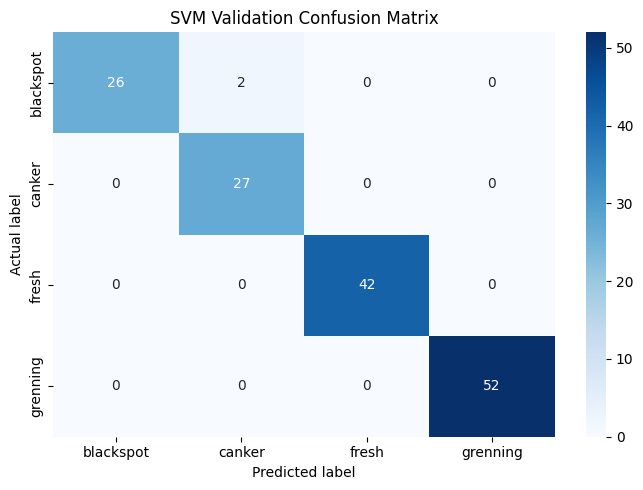

In [8]:

svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=10,
        class_weight="balanced"
    ))
])

print("Training SVM...")
svm_model.fit(Xtr, y_train)

val_predictions = svm_model.predict(Xv)

print("\nValidation accuracy:",
      round(accuracy_score(y_val, val_predictions), 4))

print("\nClassification report:")
print(classification_report(
    y_val,
    val_predictions,
    zero_division=0
))

labels_order = sorted(set(labels))
cm = confusion_matrix(
    y_val, val_predictions, labels=labels_order
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=labels_order,
    yticklabels=labels_order
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("SVM Validation Confusion Matrix")
plt.tight_layout()
plt.show()


In [9]:
from pathlib import Path
import joblib

output_dir = Path("/content/orange_outputs")
output_dir.mkdir(exist_ok=True)

joblib.dump(
    svm_model,
    output_dir / "orange_svm.joblib"
)

print("Model saved:", output_dir / "orange_svm.joblib")

Model saved: /content/orange_outputs/orange_svm.joblib


In [10]:

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchvision.models import MobileNet_V2_Weights
from pathlib import Path
import numpy as np
import random

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

data_dir = Path("/content/orange_dataset")
train_dir = data_dir / "train"
test_dir = data_dir / "test"

IMG_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.15, contrast=0.15, saturation=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Split the original training folder into training and validation subsets
full_train = datasets.ImageFolder(train_dir)
class_names = full_train.classes
print("Classes:", class_names)

train_indices, val_indices = train_test_split(
    np.arange(len(full_train)),
    test_size=0.15,
    random_state=SEED,
    stratify=full_train.targets
)

# Use separate dataset instances so validation receives no augmentation
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
val_dataset = datasets.ImageFolder(train_dir, transform=eval_transform)

from torch.utils.data import Subset

train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(val_dataset, val_indices)

train_loader = DataLoader(
    train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2
)
val_loader = DataLoader(
    val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2
)

print("Training:", len(train_subset))
print("Validation:", len(val_subset))


Device: cuda
Classes: ['blackspot', 'canker', 'fresh', 'grenning']
Training: 842
Validation: 149


In [11]:

weights = MobileNet_V2_Weights.DEFAULT
model = models.mobilenet_v2(weights=weights)

# Freeze the pretrained feature extractor initially
for param in model.features.parameters():
    param.requires_grad = False

# Replace the final classification layer for our four classes
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, len(class_names))

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.classifier.parameters(), lr=0.001
)

print("MobileNetV2 ready!")


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 95.6MB/s]


MobileNetV2 ready!


In [12]:

from sklearn.metrics import accuracy_score

EPOCHS = 5
best_val_accuracy = 0.0
model_path = "/content/orange_outputs/mobilenetv2_best.pth"

Path("/content/orange_outputs").mkdir(exist_ok=True)

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, targets in train_loader:
        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == targets).sum().item()
        train_total += targets.size(0)

    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)
            targets = targets.to(device)
            outputs = model(images)
            val_correct += (
                outputs.argmax(1) == targets
            ).sum().item()
            val_total += targets.size(0)

    train_accuracy = train_correct / train_total
    val_accuracy = val_correct / val_total

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Loss: {train_loss/train_total:.4f} | "
        f"Train accuracy: {train_accuracy:.4f} | "
        f"Validation accuracy: {val_accuracy:.4f}"
    )

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names": class_names
        }, model_path)

print("Best validation accuracy:", round(best_val_accuracy, 4))
print("Best model saved to:", model_path)


Epoch 1/5 | Loss: 0.8385 | Train accuracy: 0.7411 | Validation accuracy: 0.9799
Epoch 2/5 | Loss: 0.3351 | Train accuracy: 0.9691 | Validation accuracy: 0.9799
Epoch 3/5 | Loss: 0.2243 | Train accuracy: 0.9679 | Validation accuracy: 0.9866
Epoch 4/5 | Loss: 0.1721 | Train accuracy: 0.9715 | Validation accuracy: 1.0000
Epoch 5/5 | Loss: 0.1397 | Train accuracy: 0.9786 | Validation accuracy: 0.9933
Best validation accuracy: 1.0
Best model saved to: /content/orange_outputs/mobilenetv2_best.pth


              precision    recall  f1-score   support

   blackspot       1.00      1.00      1.00        28
      canker       1.00      1.00      1.00        27
       fresh       1.00      1.00      1.00        42
    grenning       1.00      1.00      1.00        52

    accuracy                           1.00       149
   macro avg       1.00      1.00      1.00       149
weighted avg       1.00      1.00      1.00       149



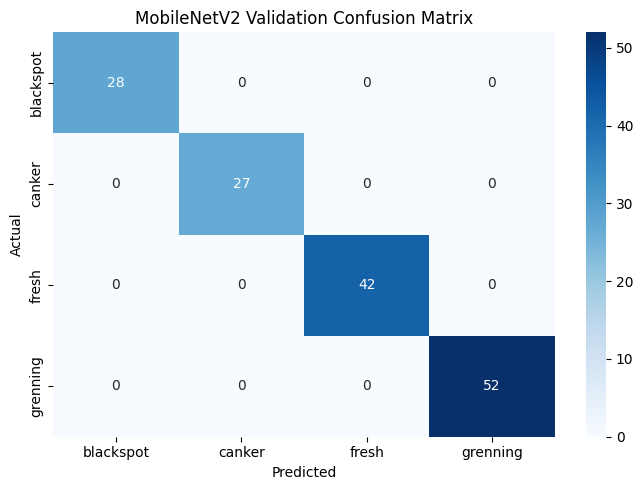

In [13]:

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

checkpoint = torch.load(model_path, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_true = []
all_pred = []

with torch.no_grad():
    for images, targets in val_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(1).cpu().numpy()

        all_pred.extend(predictions)
        all_true.extend(targets.numpy())

print(classification_report(
    all_true,
    all_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    all_true, all_pred, labels=list(range(len(class_names)))
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("MobileNetV2 Validation Confusion Matrix")
plt.tight_layout()
plt.show()


Test images: 99

SVM test results:
              precision    recall  f1-score   support

   blackspot       0.95      0.95      0.95        22
      canker       0.95      0.95      0.95        22
       fresh       1.00      1.00      1.00        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.98        99
   macro avg       0.98      0.98      0.98        99
weighted avg       0.98      0.98      0.98        99

SVM metrics: {'accuracy': 0.9798, 'macro_precision': 0.9773, 'macro_recall': 0.9773, 'macro_f1': 0.9773}


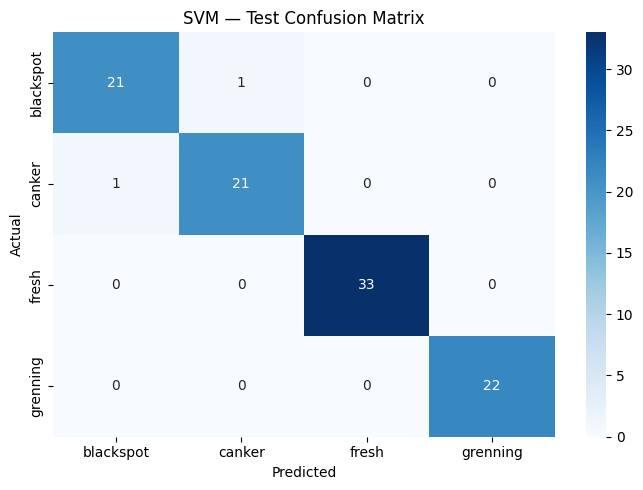

In [14]:

from pathlib import Path
import numpy as np
import joblib
import json
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

data_dir = Path("/content/orange_dataset")
test_dir = data_dir / "test"
output_dir = Path("/content/orange_outputs")
output_dir.mkdir(exist_ok=True)

# Load the saved SVM model
svm_model = joblib.load(output_dir / "orange_svm.joblib")

# Collect test image paths and labels
valid_ext = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
test_paths, y_test = [], []

for class_dir in sorted(test_dir.iterdir()):
    if class_dir.is_dir():
        for path in sorted(class_dir.rglob("*")):
            if path.suffix.lower() in valid_ext:
                test_paths.append(str(path))
                y_test.append(class_dir.name)

# Extract features using the same function used for training
X_test = np.array([extract_features(p) for p in test_paths])

svm_predictions = svm_model.predict(X_test)

print("Test images:", len(y_test))
print("\nSVM test results:")
print(classification_report(
    y_test, svm_predictions, zero_division=0
))

svm_metrics = {
    "accuracy": accuracy_score(y_test, svm_predictions),
    "macro_precision": precision_score(
        y_test, svm_predictions, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_test, svm_predictions, average="macro", zero_division=0
    ),
    "macro_f1": f1_score(
        y_test, svm_predictions, average="macro", zero_division=0
    )
}

print("SVM metrics:", {
    k: round(v, 4) for k, v in svm_metrics.items()
})

test_classes = sorted(set(y_test))
cm = confusion_matrix(y_test, svm_predictions, labels=test_classes)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=test_classes, yticklabels=test_classes
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM — Test Confusion Matrix")
plt.tight_layout()
plt.show()


MobileNetV2 test results:
              precision    recall  f1-score   support

   blackspot       0.91      0.91      0.91        22
      canker       0.89      0.77      0.83        22
       fresh       0.92      1.00      0.96        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.93        99
   macro avg       0.93      0.92      0.92        99
weighted avg       0.93      0.93      0.93        99

MobileNetV2 metrics: {'accuracy': 0.9293, 'macro_precision': 0.9301, 'macro_recall': 0.9205, 'macro_f1': 0.9237}


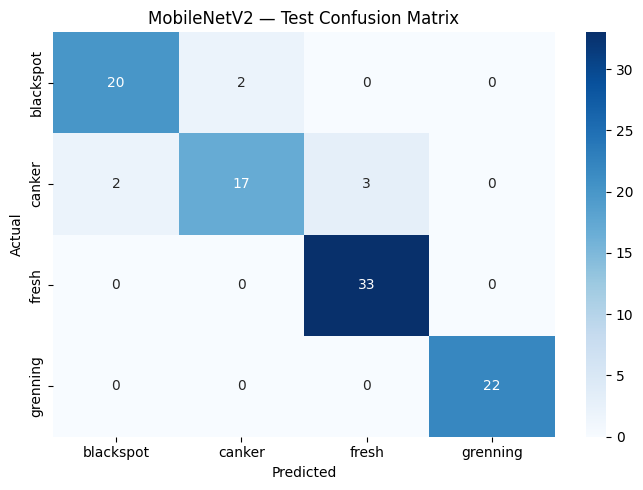

In [15]:

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_path = "/content/orange_outputs/mobilenetv2_best.pth"

checkpoint = torch.load(model_path, map_location=device)
class_names = checkpoint["class_names"]

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset = datasets.ImageFolder(
    "/content/orange_dataset/test",
    transform=eval_transform
)

assert test_dataset.classes == class_names, (
    f"Class mismatch! Model: {class_names}; "
    f"Test data: {test_dataset.classes}"
)

test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False, num_workers=2
)

model = models.mobilenet_v2(weights=None)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features, len(class_names)
)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

dl_true, dl_pred = [], []

with torch.no_grad():
    for images, targets in test_loader:
        outputs = model(images.to(device))
        predictions = outputs.argmax(dim=1).cpu().numpy()
        dl_pred.extend(predictions)
        dl_true.extend(targets.numpy())

print("MobileNetV2 test results:")
print(classification_report(
    dl_true,
    dl_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

dl_metrics = {
    "accuracy": accuracy_score(dl_true, dl_pred),
    "macro_precision": precision_score(
        dl_true, dl_pred, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        dl_true, dl_pred, average="macro", zero_division=0
    ),
    "macro_f1": f1_score(
        dl_true, dl_pred, average="macro", zero_division=0
    )
}

print("MobileNetV2 metrics:", {
    k: round(v, 4) for k, v in dl_metrics.items()
})

cm = confusion_matrix(
    dl_true, dl_pred, labels=list(range(len(class_names)))
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("MobileNetV2 — Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [16]:

import pandas as pd

comparison = pd.DataFrame(
    [svm_metrics, dl_metrics],
    index=["SVM", "MobileNetV2"]
)

print(comparison.round(4))
comparison.to_csv(output_dir / "model_comparison.csv")
comparison.to_json(output_dir / "model_comparison.json", indent=2)

print("\nComparison saved to:", output_dir / "model_comparison.csv")


             accuracy  macro_precision  macro_recall  macro_f1
SVM            0.9798           0.9773        0.9773    0.9773
MobileNetV2    0.9293           0.9301        0.9205    0.9237

Comparison saved to: /content/orange_outputs/model_comparison.csv


Saving c (120).jpg to c (120).jpg


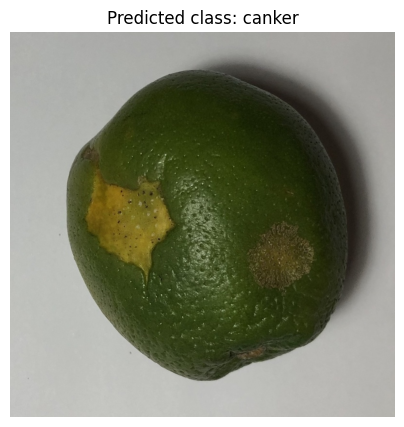

Predicted orange condition: canker


In [18]:

from google.colab import files
from pathlib import Path
import cv2
import numpy as np
import joblib
import matplotlib.pyplot as plt

svm_model = joblib.load(
    "/content/orange_outputs/orange_svm.joblib"
)

uploaded_image = files.upload()
image_path = next(iter(uploaded_image.keys()))

features = extract_features(image_path).reshape(1, -1)
prediction = svm_model.predict(features)[0]

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.title(f"Predicted class: {prediction}")
plt.show()

print("Predicted orange condition:", prediction)


In [19]:

import pandas as pd
import json
from pathlib import Path

output_dir = Path("/content/orange_outputs")
output_dir.mkdir(exist_ok=True)

# Save the comparison
comparison.to_csv(output_dir / "model_comparison.csv")

# Save detailed metrics
with open(output_dir / "final_metrics.json", "w") as f:
    json.dump({
        "dataset": "Orange Condition Classification",
        "test_images": len(y_test),
        "svm": {k: float(v) for k, v in svm_metrics.items()},
        "mobilenetv2": {k: float(v) for k, v in dl_metrics.items()},
        "selected_model": "SVM"
    }, f, indent=2)

# Save individual SVM test predictions
pd.DataFrame({
    "image_path": test_paths,
    "actual_class": y_test,
    "predicted_class": svm_predictions
}).to_csv(output_dir / "svm_test_predictions.csv", index=False)

print("Final results saved in:", output_dir)
print("Files:", [p.name for p in output_dir.iterdir()])


Final results saved in: /content/orange_outputs
Files: ['final_metrics.json', 'model_comparison.csv', 'svm_test_predictions.csv', 'mobilenetv2_best.pth', 'model_comparison.json', 'orange_svm.joblib']


In [20]:
from google.colab import files
import shutil

shutil.make_archive(
    "/content/orange_outputs",
    "zip",
    "/content/orange_outputs"
)

files.download("/content/orange_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>